# Auxotrophies and minimal medium

In [1]:
import reframed
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json

In [2]:
import sys

sys.path.append("../functions/")
from minimal_medium import make_minimal_media_df

In [3]:
%load_ext autoreload
%autoreload 2

**Set gurobi as default solver**

In [4]:
reframed.set_default_solver("gurobi")

**Load other data (E. coli)**

In [5]:
relative_abundance_ecoli = pd.read_csv("../data/Guillen2021/relative_abundance.csv",index_col=0)
relative_abundance_ecoli.index = relative_abundance_ecoli.index.map(lambda x:x if x!="yhhK" else "panZ")

gene_id2name = pd.read_csv("../data/Guillen2021/generated/gene_id2name.tsv",sep="\t")

**Load models**

*E. coli mutants  (top 7) and (all 38)*

In [6]:
RA_ecoli_mean = relative_abundance_ecoli.T.mean().sort_values(ascending=False)
top7 = RA_ecoli_mean[RA_ecoli_mean>0.01].index
top7_string = [f"mutant_{mutant}.xml" for mutant in top7]

In [7]:
models_ecoli = {}
models_ecoli_top7 = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    for path in listdir("../models/Guillen2021/strains/"):
        if not path.endswith(".xml"): continue
        model= reframed.load_cbmodel("../models/Guillen2021/strains/"+path,
                                     exchange_detection="^R_EX_(?!nad_c$|thf_c$).*")
        
        models_ecoli[path.split("_")[1][:-4]] = model
        
        if path not in top7_string: continue
        models_ecoli_top7[path.split("_")[1][:-4]] = model.copy()

*Gut microbiome members*

In [8]:
models_gut = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    for path in listdir("../models/Venturelli2018/species_used_noO2/"):
        models_gut[path[:-4]] = reframed.load_cbmodel("../models/Venturelli2018/species_used_noO2/"+path,
                                                      exchange_detection="R_EX_(?!biomass__40__e__41__)")


**Load media**

*For E. coli mutants (LB medium to see auxotrophies)*

In [9]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = list(media_db[media_db.medium=="LB"].compound.values)
compounds.append("btn") # biot members are auxotrophic to biotin which was not in LB-medium. 
compounds.append("mmet") # metE and metH double mutant has been shown to be dependent on mmet (S-Methylmethionine). metH is missing in the model!
compounds.append("26dap__M") # meso-DAP. Essential part of cell wall in gram-negative bacteria...
env_ecoli_lb = reframed.Environment.from_compounds(compounds)

*For gut microbiome members*

In [10]:
media_db_gut = pd.read_csv("../data/Venturelli2018/generated/media_db.tsv",sep="\t")
reactions = media_db_gut[media_db_gut.medium=="LB_extend"].compound.values
reactions = [rxn.replace("91","40").replace("93","41") for rxn in reactions]

env_gut = reframed.Environment.from_reactions(reactions)

**Translation dicts**

In [11]:
mets_id_ag = []
mets_id_bigg = []
ex_rxns_ag = []
for model in models_gut.values():
    for rxn in model.get_exchange_reactions():
        if "R_EX_" not in rxn:
            continue
        met_id_ag = model.reactions[rxn].get_substrates()[0]
        mets_id_ag.append(met_id_ag)
        met_id_bigg = model.metabolites[met_id_ag].metadata["bigg.metabolite"][0]
        mets_id_bigg.append(met_id_bigg)
        ex_rxns_ag.append(rxn)
    
met2ex = dict(zip(mets_id_bigg,ex_rxns_ag))

### Find minimal medium

In [12]:
minimal_media_df_ecoli = make_minimal_media_df(models_ecoli,
                                               env_ecoli_lb,
                                               min_growth=0.1,
                                               n_solutions=100,
                                               max_uptake=1)

Started analysis for trpA
Set parameter Username
Academic license - for non-commercial use only - expires 2026-03-27


/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/minimal_medium.py:265: UserWarning: Solution appears to be invalid.
  warn('Solution appears to be invalid.')


mutant_trpA: Objective: 2355.5509
Status: Optimal

Started analysis for pyrD
mutant_pyrD: Objective: 2151.3262
Status: Optimal

Started analysis for panZ
mutant_panZ: Objective: 2369.5526
Status: Optimal

Started analysis for trpE
mutant_trpE: Objective: 2355.5509
Status: Optimal

Started analysis for pheA
mutant_pheA: Objective: 2301.5003
Status: Optimal

Started analysis for pdxA
mutant_pdxA: Objective: 2318.4878
Status: Optimal

Started analysis for leuB
mutant_leuB: Objective: 2267.484
Status: Optimal

Started analysis for bioD
mutant_bioD: Objective: 2394.6283
Status: Optimal

Started analysis for argB
mutant_argB: Objective: 2292.5199
Status: Optimal

Started analysis for tyrA
mutant_tyrA: Objective: 2317.4997000000003
Status: Optimal

Started analysis for bioF
mutant_bioF: Objective: 2394.6283
Status: Optimal

Started analysis for argA
mutant_argA: Objective: 2292.5199
Status: Optimal

Started analysis for bioC
mutant_bioC: Objective: 2394.6283
Status: Optimal

Started analysis 

/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/minimal_medium.py:285: UserWarning: No solutions for aroC
  warn(f"No solutions for {model_id}")


mutant_nadB: Objective: 2151.3262
Status: Optimal

Started analysis for rpe
mutant_rpe: Objective: 2444.734517690385
Status: Optimal

Started analysis for cysW
mutant_cysW: Objective: 2161.4069000000004
Status: Optimal

Started analysis for purA
mutant_purA: Objective: 2151.3262
Status: Optimal

Started analysis for nadC
mutant_nadC: Objective: 2151.3262
Status: Optimal

Started analysis for purE
mutant_purE: Objective: 2151.3262
Status: Optimal

Started analysis for cysD
mutant_cysD: Objective: 2161.4069000000004
Status: Optimal

Started analysis for panD
mutant_panD: Objective: 2369.5526
Status: Optimal

Started analysis for metC
mutant_metC: Objective: 2285.5225
Status: Optimal

Started analysis for ppc
mutant_ppc: Objective: 2151.3262
Status: Optimal

Started analysis for metB
mutant_metB: Objective: 2285.5225
Status: Optimal

Started analysis for ilvE
mutant_ilvE: Objective: 2267.484
Status: Optimal

Started analysis for metA
mutant_metA: Objective: 2285.5225
Status: Optimal

Star

In [13]:
minimal_media_df_gut = make_minimal_media_df(models_gut,
                                             env_gut,
                                             min_growth=0.1,
                                             n_solutions=100,
                                             max_uptake=5)

Started analysis for Bacteroides_uniformis_ATCC_8492
M_Bacteroides_uniformis_ATCC_8492: Objective: 1341.1657
Status: Optimal

Started analysis for Bacteroides_vulgatus_ATCC_8482
M_Bacteroides_vulgatus_ATCC_8482: Objective: 4480.347400000001
Status: Optimal

Started analysis for Collinsella_aerofaciens_ATCC_25986
M_Collinsella_aerofaciens_ATCC_25986: Objective: 3342.294699999999
Status: Optimal

Started analysis for Faecalibacterium_prausnitzii_A2_165
M_Faecalibacterium_prausnitzii_A2_165: Objective: 3243.0876000000007
Status: Optimal

Started analysis for Eggerthella_lenta_DSM_2243
M_Eggerthella_lenta_DSM_2243: Objective: 5988.1361000000015
Status: Optimal

Started analysis for Prevotella_copri_CB7_DSM_18205
M_Prevotella_copri_CB7_DSM_18205: Objective: 1032.878
Status: Optimal

Started analysis for Clostridium_hiranonis_TO_931_DSM_13275
M_Clostridium_hiranonis_TO_931_DSM_13275: Objective: 3938.9033
Status: Optimal

Started analysis for Eubacterium_rectale_ATCC_33656
M_Eubacterium_recta

### Plot solutions

**Remove results for less interesting compounds**: *compounds that few members have auxotrophy for/compounds all members have auxotrophy for, and minerals etc (from M9 medium)*

In [14]:
m9_mets = media_db[media_db.medium=="M9"].compound.values
m9_rxns = ["R_EX_"+met+"_e" for met in m9_mets]
m9_rxns_gut = ["R_EX_"+met+"__40__e__41__" for met in m9_mets]

In [15]:
minimal_media_df_ecoli_plot = minimal_media_df_ecoli.loc[(minimal_media_df_ecoli.sum(axis=1)<75*minimal_media_df_ecoli.shape[1]) & (minimal_media_df_ecoli.sum(axis=1)>=90)]
minimal_media_df_ecoli_plot = minimal_media_df_ecoli_plot[~minimal_media_df_ecoli_plot.index.isin(m9_rxns)]

minimal_media_df_gut_plot = minimal_media_df_gut.loc[(minimal_media_df_gut.sum(axis=1)<75*minimal_media_df_gut.shape[1]) & (minimal_media_df_gut.sum(axis=1)>=90)]
minimal_media_df_gut_plot = minimal_media_df_gut_plot[~minimal_media_df_gut_plot.index.isin(m9_rxns_gut)]


**Define color palette**

In [16]:
bigg_met2chebi_class = pd.read_csv("../../../GEMs_from_MAGs/output/met_chebi_class.tsv",sep="\t",index_col=0)

met2chebi = bigg_met2chebi_class["self defined super class"].to_dict()
met2chebi = {key[2:-2]:value for key,value in met2chebi.items()}

agoraEx2chebi = {met2ex[key]: value for key, value in met2chebi.items() if key in met2ex.keys()}

for value in minimal_media_df_gut.index:
    if value not in agoraEx2chebi.keys():
        agoraEx2chebi[value]="undefined"

biggEx2chebi = {"R_EX_"+met+"_e":super_class for met,super_class in met2chebi.items() if "R_EX_"+met+"_e" in minimal_media_df_ecoli_plot.index}
for value in minimal_media_df_ecoli_plot.index:
    if value not in biggEx2chebi.keys():
        biggEx2chebi[value]="undefined"


pallete = sns.color_palette("tab20b",20)
pallete.reverse()
pallete2 = sns.color_palette("tab20c",20)
pallete2.reverse()
pallete.extend([pallete2[-3],pallete2[-1]])


super_classes = list(set(agoraEx2chebi.values()))+list(set(biggEx2chebi.values()))
pallete_dict = OrderedDict(zip(super_classes,pallete))
pallete_series_agora = pd.Series({key:pallete_dict[value] for key,value in agoraEx2chebi.items()} )
pallete_series_bigg = pd.Series({key:pallete_dict[value] for key,value in biggEx2chebi.items()} )


#### Members of E.coli mutants

In [17]:
import matplotlib.pyplot as plt

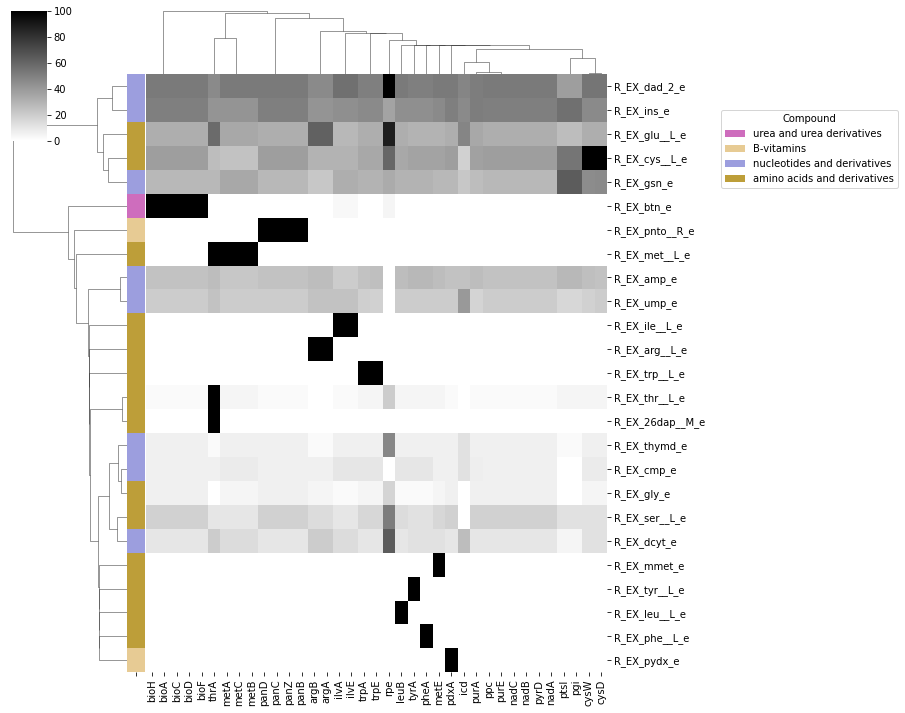

In [18]:
from matplotlib.pyplot import gcf

g = sns.clustermap(minimal_media_df_ecoli_plot,
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   xticklabels=1,
                   yticklabels=1)

relevant_classes = list(set([biggEx2chebi[key] for key in minimal_media_df_ecoli_plot.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Compound',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)

plt.savefig("figures_meeting/minimal_medium_ecoli.png",bbox_inches="tight")

**Find experimental results for top 7 members**

In [19]:
RA_ecoli_mean = relative_abundance_ecoli.T.mean().sort_values(ascending=False)
RA_ecoli_mean[RA_ecoli_mean>0.01]

icd     0.287848
panZ    0.276678
bioH    0.211130
bioF    0.098526
cysW    0.062219
bioC    0.020200
panD    0.015948
dtype: float64

In [20]:
from minimal_medium import minimal_medium

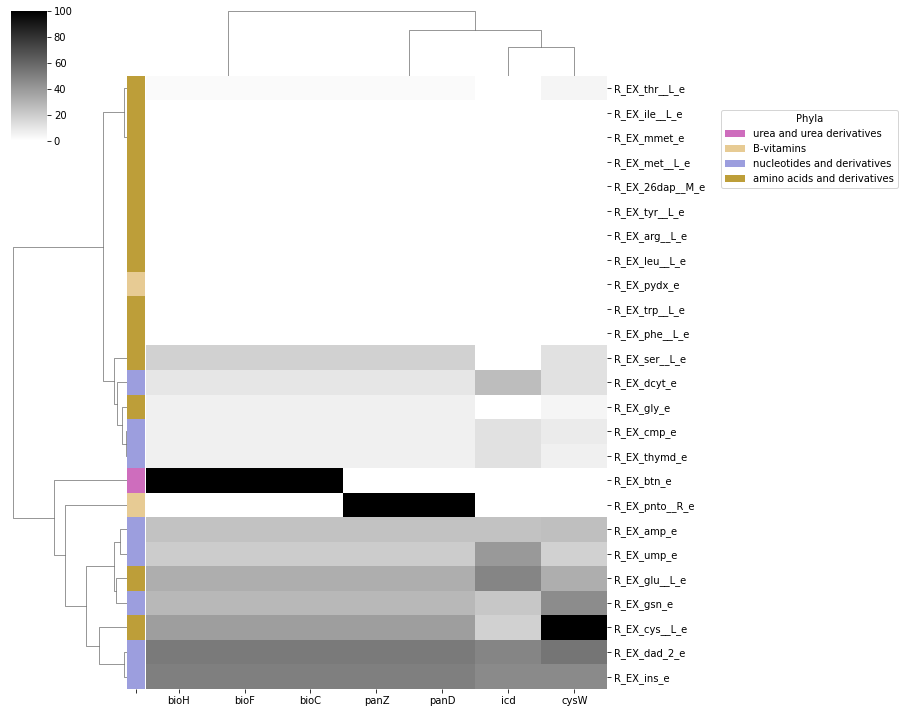

In [21]:
relevant_ecoli_mutants = RA_ecoli_mean[RA_ecoli_mean>0.01].index
minimal_media_df_ecoli_plot2 = minimal_media_df_ecoli_plot.loc[:,minimal_media_df_ecoli_plot.columns.isin(relevant_ecoli_mutants)]

g = sns.clustermap(minimal_media_df_ecoli_plot2,
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   xticklabels=1)

relevant_classes = list(set([biggEx2chebi[key] for key in minimal_media_df_ecoli_plot2.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)

<span style="color:red"> NB! bio(*) strains are auxotrophic to biotin (btn) - confirmed by removing from media.  I don't understand why it doesn't show...

In [22]:
bio_members = ["bioH","bioF","bioC","panZ"] #panZ for control


In [23]:
env_ecoli_no_btn = env_ecoli_lb.copy()
env_ecoli_no_btn.pop("R_EX_btn_e")


(-10.0, inf)

In [24]:
for mutant in bio_members:
    model = models_ecoli[mutant].copy()
    
    
    env_ecoli_no_btn.apply(model,inplace=True,exclusive=True,warning=False)
    
    sol_nobtn = reframed.FBA(model)
    env_ecoli_lb.apply(model,inplace=True,exclusive=True,warning=False)
    sol = reframed.FBA(model)
    print(f"{mutant}: With btn in media {sol.fobj}, No btn in media:{sol_nobtn.fobj} ")
    

bioH: With btn in media 3.433764771953401, No btn in media:-0.0 
bioF: With btn in media 3.433764771953401, No btn in media:-0.0 
bioC: With btn in media 3.433764771953401, No btn in media:-0.0 
panZ: With btn in media 3.4337647719533995, No btn in media:3.4320306027668255 


#### Members of gut microbiome

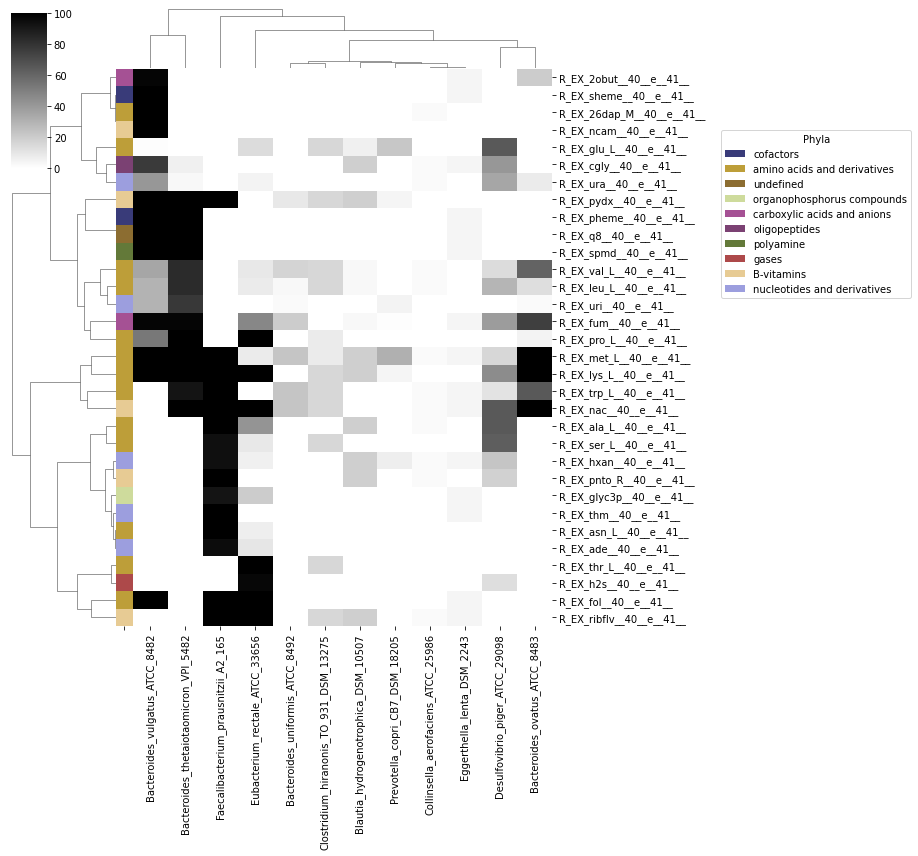

In [25]:
g = sns.clustermap(minimal_media_df_gut_plot,
                   figsize=(10,12),
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_agora,
                   xticklabels=1)

relevant_classes = list(set([agoraEx2chebi[key] for key in minimal_media_df_gut_plot.index]))

for label in relevant_classes:
    g.ax_col_dendrogram.bar(0, 0, color=pallete_dict[label], label=label, linewidth=0)
l1 = g.ax_col_dendrogram.legend(title='Phyla',ncol=1, bbox_to_anchor=(1.0, 0.85), loc='upper left',bbox_transform=gcf().transFigure)

#g.savefig("figures_meeting/minimal_medium_gut.png")

## Auxotrophies

In [26]:
from reframed.cobra import auxotrophy

### E. coli mutants

In [27]:
auxotrophies_ecoli = {}
for model_id,model in models_ecoli.items():
    print(f"Started analysis for {model_id}")
    model_copy = model.copy()
    constraints = {rxn:(0,1000) for rxn in model_copy.get_exchange_reactions()}
    
    rxns_env = [rxn.replace("91","40").replace("93","41") for rxn in env_ecoli_lb.keys()]
    constraints_env = {rxn: (-10,1000) for rxn in rxns_env if rxn in model_copy.reactions}
    constraints.update(constraints_env)
    auxotrophies_spec = auxotrophy.auxotrophies(model_copy,constraints=constraints)
    if not auxotrophies_spec:
        continue
    for aux in auxotrophies_spec:
        auxotrophies_ecoli[(model_id,aux)]=1

Started analysis for trpA
Started analysis for pyrD
Started analysis for panZ
Started analysis for trpE
Started analysis for pheA
Started analysis for pdxA
Started analysis for leuB
Started analysis for bioD
Started analysis for argB
Started analysis for tyrA
Started analysis for bioF
Started analysis for argA
Started analysis for bioC
Started analysis for ptsI
Started analysis for bioA
Started analysis for icd
Started analysis for thrA
Started analysis for bioH
Started analysis for nadA
Started analysis for panB
Started analysis for metE
Started analysis for panC
Started analysis for ilvA
Started analysis for aroC


/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/cobra/auxotrophy.py:18: UserWarning: Organism does not grow in given medium.
  warn("Organism does not grow in given medium.")


Started analysis for nadB
Started analysis for rpe
Started analysis for cysW
Started analysis for purA
Started analysis for nadC
Started analysis for purE
Started analysis for cysD
Started analysis for panD
Started analysis for metC
Started analysis for ppc
Started analysis for metB
Started analysis for ilvE
Started analysis for metA
Started analysis for pgi


In [28]:
auxotrophies_ecoli_df = pd.Series(auxotrophies_ecoli).unstack().fillna(0).T
auxotrophies_ecoli_df = auxotrophies_ecoli_df.loc[auxotrophies_ecoli_df.T.sum()!=len(auxotrophies_ecoli_df.columns)]

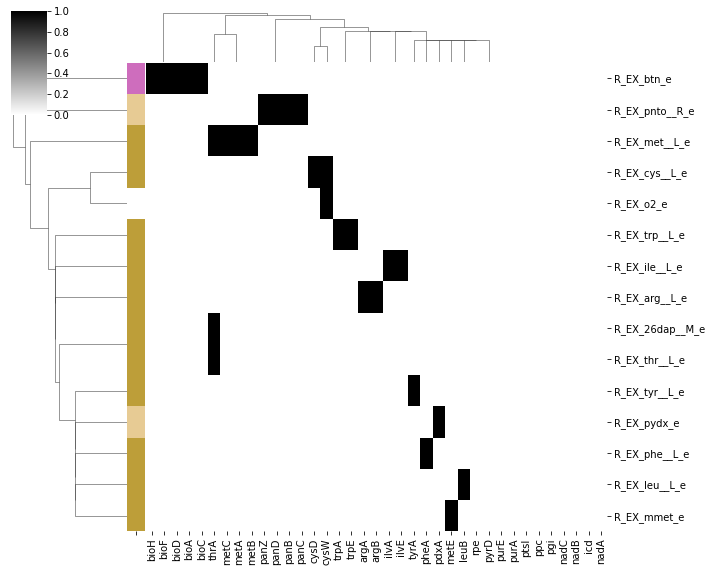

In [29]:
g = sns.clustermap(auxotrophies_ecoli_df,
                   figsize=(10,8),
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_bigg,
                   yticklabels=1,
                   xticklabels=1)

### Gut microbiome

In [30]:
auxotrophies_gut = {}
for model_id,model in models_gut.items():
    print(f"Started analysis for {model_id}")
    model_copy = model.copy()
    constraints = {rxn:(0,1000) for rxn in model_copy.get_exchange_reactions()}
    
    rxns_env = [rxn.replace("91","40").replace("93","41") for rxn in env_gut.keys()]
    constraints_env = {rxn: (-10,1000) for rxn in rxns_env if rxn in model_copy.reactions}
    constraints.update(constraints_env)
    auxotrophies_spec = auxotrophy.auxotrophies(model_copy,constraints=constraints)
    
    for aux in auxotrophies_spec:
        auxotrophies_gut[(model_id,aux)]=1

Started analysis for Bacteroides_uniformis_ATCC_8492
Started analysis for Bacteroides_vulgatus_ATCC_8482
Started analysis for Collinsella_aerofaciens_ATCC_25986
Started analysis for Faecalibacterium_prausnitzii_A2_165
Started analysis for Eggerthella_lenta_DSM_2243
Started analysis for Prevotella_copri_CB7_DSM_18205
Started analysis for Clostridium_hiranonis_TO_931_DSM_13275
Started analysis for Eubacterium_rectale_ATCC_33656
Started analysis for Desulfovibrio_piger_ATCC_29098
Started analysis for Bacteroides_ovatus_ATCC_8483
Started analysis for Bacteroides_thetaiotaomicron_VPI_5482
Started analysis for Blautia_hydrogenotrophica_DSM_10507


In [31]:
auxotrophies_gut_df = pd.Series(auxotrophies_gut).unstack().fillna(0).T
auxotrophies_gut_df = auxotrophies_gut_df.loc[auxotrophies_gut_df.T.sum()!=len(auxotrophies_gut_df.columns)]


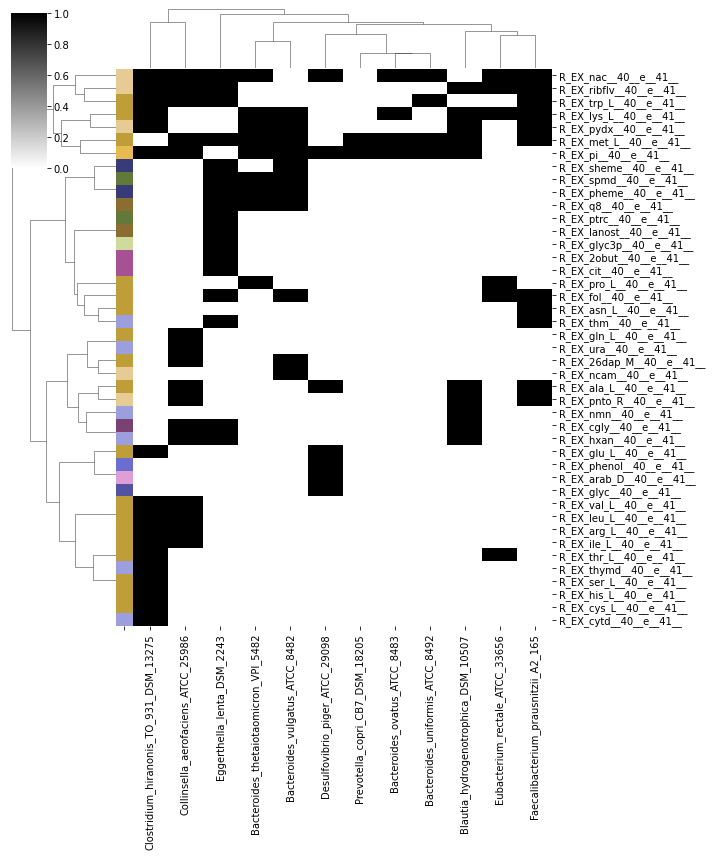

In [32]:
g = sns.clustermap(auxotrophies_gut_df,
                   figsize=(10,12),
                   cmap="binary",
                   method="ward",
                   vmin=0,
                   fmt="d",
                   dendrogram_ratio=(0.2, 0.1),
                   row_colors=pallete_series_agora,
                   xticklabels=1)

In [33]:
auxotrophies_ecoli_df_stack = auxotrophies_ecoli_df.T.stack()

auxotrophies_ecoli_df_stack = auxotrophies_ecoli_df_stack[auxotrophies_ecoli_df_stack!=0].sort_index()
auxotrophies_ecoli_df_stack.index.names = ["member","compound"]
auxotrophies_ecoli_df_stack.to_csv("../output/Guillen2021/auxotrophies.tsv",sep="\t")

In [34]:
auxotrophies_gut_df_stack = auxotrophies_gut_df.T.stack()

auxotrophies_gut_df_stack = auxotrophies_gut_df_stack[auxotrophies_gut_df_stack!=0].sort_index()
auxotrophies_gut_df_stack.index.names = ["member","compound"]
auxotrophies_gut_df_stack.to_csv("../output/Venturelli2018/auxotrophies.tsv",sep="\t")

## Check community growth

**Load media**

*For E. coli mutants (M9 medium to see if they can grow together)*

In [35]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = list(media_db[media_db.medium=="M9"].compound.values)
env_ecoli_m9 = reframed.Environment.from_compounds(compounds,max_uptake=50)

*For gut microbiome members*

In [36]:
media_db_gut = pd.read_csv("../data/Venturelli2018/generated/media_db.tsv",sep="\t")
reactions = media_db_gut[media_db_gut.medium=="LB_extend"].compound.values
env_gut = reframed.Environment.from_reactions(reactions,max_uptake=10)

### Check community growth

**Make community model**

*For E. coli mutants*

In [37]:
comm_ecoli = reframed.Community(models=models_ecoli_top7.values(),community_id="ecoli_mutants")

*For gut microbiome members*

In [38]:
comm_gut = reframed.Community(models=models_gut.values(),community_id="gut_microbiome")

#### Ecoli mutants community growth

In [39]:
env_ecoli_m9.apply(comm_ecoli.merged_model, inplace=True, exclusive=True, warning=False)

biomass_rxns = comm_ecoli.merged_model.get_metabolite_producers("community_biomass")
growth = np.ones(len(biomass_rxns))*0.1
growth_upper = np.ones(len(biomass_rxns))*1000
constraints_growth_ecoli = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))

In [40]:
sol = reframed.FBA(comm_ecoli.merged_model,
                   constraints=constraints_growth_ecoli
                  )
sol.values["community_growth"]

2.5413888975782113

In [41]:
for rxn in biomass_rxns:
    print(f"{rxn}: {sol.values[rxn]}")

R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panZ: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioF: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioC: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_icd: 1.9413888975782114
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_bioH: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_cysW: 0.1
R_BIOMASS_Ec_iML1515_core_75p37M_mutant_panD: 0.1


#### Gut microbiome community growth

In [42]:
env_gut.apply(comm_gut.merged_model, inplace=True, exclusive=True, warning=False)

biomass_rxns = comm_gut.merged_model.get_metabolite_producers("community_biomass")
growth = np.ones(len(biomass_rxns))*0.1
growth_upper = np.ones(len(biomass_rxns))*1000
constraints_growth_gut = dict(zip(biomass_rxns,list(zip(growth,growth_upper))))

In [43]:
sol = reframed.FBA(comm_gut.merged_model,constraints=constraints_growth_gut)

sol.values["community_growth"]

21.49757044065601

In [44]:
for rxn in biomass_rxns:
    print(f"{rxn}: {sol.values[rxn]}")

R_biomass536_M_Bacteroides_uniformis_ATCC_8492: 0.1
R_biomass345_M_Bacteroides_vulgatus_ATCC_8482: 18.261651457341802
R_biomass524_M_Collinsella_aerofaciens_ATCC_25986: 0.1
R_biomass223_M_Faecalibacterium_prausnitzii_A2_165: 0.1
R_biomass467_M_Eggerthella_lenta_DSM_2243: 0.1
R_biomass525_M_Prevotella_copri_CB7_DSM_18205: 0.1
R_biomass525_M_Clostridium_hiranonis_TO_931_DSM_13275: 0.1
R_biomass205_M_Eubacterium_rectale_ATCC_33656: 0.1
R_biomass525_M_Desulfovibrio_piger_ATCC_29098: 0.1
R_biomass536_M_Bacteroides_ovatus_ATCC_8483: 0.1
R_biomass345_M_Bacteroides_thetaiotaomicron_VPI_5482: 2.2359189833142055
R_biomass525_M_Blautia_hydrogenotrophica_DSM_10507: 0.1
